In [1]:
print("Лабораторна робота з машинного навчання")
print("Лінійна регресія — початок роботи")

Лабораторна робота з машинного навчання
Лінійна регресія — початок роботи


# Лабораторна робота: Лінійна регресія

**Дисципліна:** Машинне навчання

**Мета роботи:** дослідити принципи роботи лінійної регресії, реалізувати алгоритми градієнтного спуску, оцінити якість моделі за допомогою метрик та перевірити статистичні припущення.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import ssl
import certifi
import torch


os.environ["SSL_CERT_FILE"] = certifi.where()
os.environ["REQUESTS_CA_BUNDLE"] = certifi.where()

ssl._create_default_https_context = lambda: ssl.create_default_context(
    cafile=certifi.where()
)

print("Сертифікати налаштовано:", certifi.where())
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from IPython.display import display

print("Бібліотеки успішно імпортовано!")
print("Версія NumPy:", np.__version__)
print("Версія Pandas:", pd.__version__)
print("Версія PyTorch:", torch.__version__)

Сертифікати налаштовано: /Users/ulianaksondz/Documents/linear_regression_lab/.venv/lib/python3.13/site-packages/certifi/cacert.pem
Бібліотеки успішно імпортовано!
Версія NumPy: 2.5.4
Версія Pandas: 3.0.6
Версія PyTorch: 2.14.1


In [10]:
housing = fetch_openml(
    name="house_prices",
    as_frame=True,
    parser="auto"
)

df = housing.frame.copy()

print("Розмір датасету:", df.shape)
print("\nПерші 5 рядків:")
display(df.head())

URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1028)>

In [12]:
from sklearn.datasets import fetch_openml

housing = fetch_openml(
    name="house_prices",
    as_frame=True,
    parser="auto"
)

df = housing.frame.copy()

print("Розмір датасету:", df.shape)
display(df.head())

URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1028)>

In [13]:
import sys
import ssl
import certifi
import urllib.request

print("Python:", sys.executable)
print("Сертифікати certifi:", certifi.where())
print("Стандартні шляхи SSL:", ssl.get_default_verify_paths())

try:
    with urllib.request.urlopen(
        "https://www.openml.org",
        context=ssl.create_default_context(cafile=certifi.where()),
        timeout=15
    ) as response:
        print("OpenML доступний, HTTP:", response.status)
except Exception as e:
    print(type(e).__name__, str(e))

Python: /Users/ulianaksondz/Documents/linear_regression_lab/.venv/bin/python
Сертифікати certifi: /Users/ulianaksondz/Documents/linear_regression_lab/.venv/lib/python3.13/site-packages/certifi/cacert.pem
Стандартні шляхи SSL: DefaultVerifyPaths(cafile='/Users/ulianaksondz/Documents/linear_regression_lab/.venv/lib/python3.13/site-packages/certifi/cacert.pem', capath=None, openssl_cafile_env='SSL_CERT_FILE', openssl_cafile='/Library/Frameworks/Python.framework/Versions/3.13/etc/openssl/cert.pem', openssl_capath_env='SSL_CERT_DIR', openssl_capath='/Library/Frameworks/Python.framework/Versions/3.13/etc/openssl/certs')
OpenML доступний, HTTP: 200


In [14]:
import ssl
import certifi
import urllib.request
from sklearn.datasets import fetch_openml

ssl_context = ssl.create_default_context(cafile=certifi.where())

opener = urllib.request.build_opener(
    urllib.request.HTTPSHandler(context=ssl_context)
)

urllib.request.install_opener(opener)

housing = fetch_openml(
    name="house_prices",
    as_frame=True,
    parser="auto"
)

df = housing.frame.copy()

print("Розмір датасету:", df.shape)
display(df.head())

Розмір датасету: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Первинний аналіз даних

На цьому етапі досліджується набір даних Ames Housing, який містить характеристики житлових будинків та інформацію про ціну їх продажу. Мета аналізу — визначити структуру набору, типи ознак, наявність пропущених значень і взаємозв'язки між характеристиками нерухомості та її вартістю.

In [15]:
print("Розмір датасету:", df.shape)

print("\nТипи даних:")
display(df.dtypes.value_counts().to_frame("Кількість стовпців"))

print("\nІнформація про стовпці:")
df.info()

Розмір датасету: (1460, 81)

Типи даних:


,Кількість стовпців
str,43
int64,35
float64,3



Інформація про стовпці:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  

In [16]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [17]:
missing = pd.DataFrame({
    "Пропущено": df.isna().sum(),
    "Відсоток (%)": df.isna().mean() * 100
})

missing = missing[missing["Пропущено"] > 0]
missing = missing.sort_values("Відсоток (%)", ascending=False)

print("Кількість стовпців із пропусками:", len(missing))
display(missing.head(20))

Кількість стовпців із пропусками: 19


,Пропущено,Відсоток (%)
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945
GarageQual,81,5.547945


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


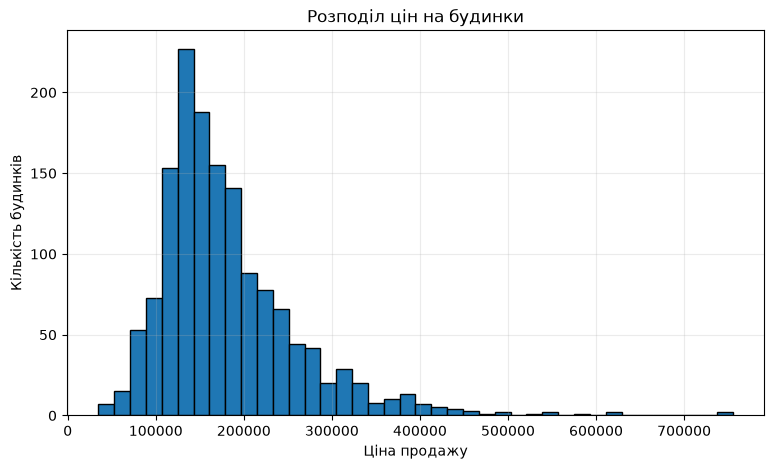

In [18]:
print(df["SalePrice"].describe())

plt.figure(figsize=(9, 5))
plt.hist(df["SalePrice"], bins=40, edgecolor="black")
plt.title("Розподіл цін на будинки")
plt.xlabel("Ціна продажу")
plt.ylabel("Кількість будинків")
plt.grid(alpha=0.25)
plt.show()

10 ознак із найсильнішим лінійним зв'язком із ціною:


,Кореляція із SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


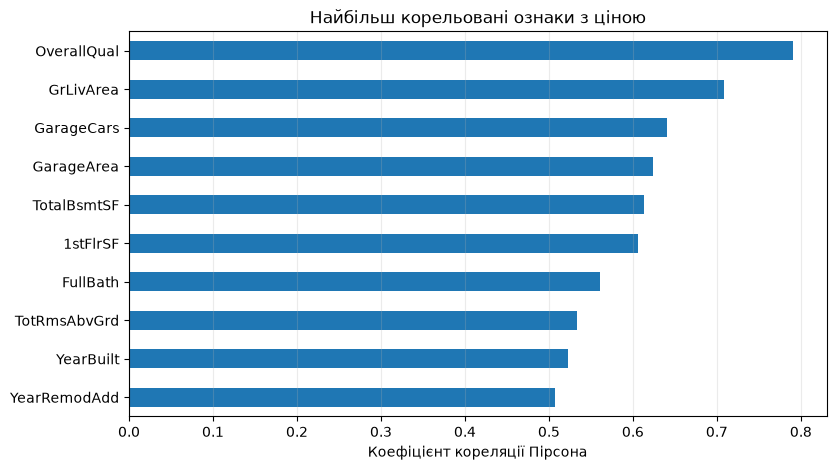

In [19]:
numeric_df = df.select_dtypes(include=np.number)

correlations = numeric_df.corr(numeric_only=True)["SalePrice"]
correlations = correlations.drop("SalePrice").sort_values(
    key=abs, ascending=False
)

print("10 ознак із найсильнішим лінійним зв'язком із ціною:")
display(correlations.head(10).to_frame("Кореляція із SalePrice"))

plt.figure(figsize=(9, 5))
correlations.head(10).sort_values().plot(kind="barh")
plt.title("Найбільш корельовані ознаки з ціною")
plt.xlabel("Коефіцієнт кореляції Пірсона")
plt.grid(axis="x", alpha=0.25)
plt.show()

## 2. Підготовка даних

На цьому етапі відокремлюється цільова змінна `SalePrice` від вхідних ознак. Ідентифікатор будинку `Id` не використовується для прогнозування, оскільки він не характеризує властивості нерухомості. Дані розділяються на навчальну, валідаційну та тестову вибірки. Пропущені значення й масштабування ознак обробляються без використання інформації з валідаційної та тестової вибірок.

In [20]:
from sklearn.model_selection import train_test_split

# Залишаємо рядки, для яких відома ціна будинку
df_model = df.dropna(subset=["SalePrice"]).copy()

# Відокремлюємо цільову змінну від ознак
X = df_model.drop(columns=["SalePrice", "Id"], errors="ignore")
y = pd.to_numeric(df_model["SalePrice"], errors="coerce")

# Залишаємо тільки рядки з коректною цільовою змінною
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# Спочатку відокремлюємо тестову вибірку — 20%
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Із решти даних виділяємо валідаційну вибірку — 20% загального набору
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25, random_state=42
)

print("Навчальна вибірка:", X_train.shape, y_train.shape)
print("Валідаційна вибірка:", X_val.shape, y_val.shape)
print("Тестова вибірка:", X_test.shape, y_test.shape)

print("\nПропущені значення у цільовій змінній:")
print("Train:", y_train.isna().sum())
print("Validation:", y_val.isna().sum())
print("Test:", y_test.isna().sum())

Навчальна вибірка: (876, 79) (876,)
Валідаційна вибірка: (292, 79) (292,)
Тестова вибірка: (292, 79) (292,)

Пропущені значення у цільовій змінній:
Train: 0
Validation: 0
Test: 0


## 3. Попередня обробка ознак

Для підготовки даних до навчання моделі числові та категоріальні ознаки обробляються окремо. Пропущені значення числових ознак замінюються медіаною, а категоріальних — найчастішим значенням. Категоріальні змінні кодуються методом One-Hot Encoding. Для числової стабільності та коректного порівняння ваг ознаки стандартизуються. Усі параметри попередньої обробки визначаються лише за навчальною вибіркою.

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Визначаємо числові та категоріальні ознаки
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Кількість числових ознак:", len(numeric_features))
print("Кількість категоріальних ознак:", len(categorical_features))

# Обробка числових ознак
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Обробка категоріальних ознак
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Об'єднуємо обидва процеси
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Навчаємо попередню обробку лише на train
X_train_processed = preprocessor.fit_transform(X_train)

# До інших вибірок застосовуємо вже навчені перетворення
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Перетворюємо розріджені матриці на звичайні масиви
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_val_processed, "toarray"):
    X_val_processed = X_val_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Перетворюємо дані на float32
X_train_processed = X_train_processed.astype(np.float32)
X_val_processed = X_val_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

print("\nРозмір після обробки:")
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

print("\nПропущені значення після обробки:")
print("Train:", np.isnan(X_train_processed).sum())
print("Validation:", np.isnan(X_val_processed).sum())
print("Test:", np.isnan(X_test_processed).sum())

Кількість числових ознак: 36
Кількість категоріальних ознак: 43

Розмір після обробки:
Train: (876, 282)
Validation: (292, 282)
Test: (292, 282)

Пропущені значення після обробки:
Train: 0
Validation: 0
Test: 0


## 4. Реалізація лінійної регресії з нуля

Лінійна регресія використовується для прогнозування числової цільової змінної на основі вхідних ознак. У цій роботі модель реалізується самостійно за допомогою PyTorch без використання готових регресійних моделей.

Навчання виконується шляхом мінімізації середньоквадратичної помилки (MSE). Для оптимізації параметрів використовуються пакетний градієнтний спуск (Batch Gradient Descent), стохастичний градієнтний спуск (SGD) і мініпакетний градієнтний спуск (Mini-batch Gradient Descent).

In [24]:
import torch

# Фіксуємо випадковість для відтворюваності результатів
np.random.seed(42)
torch.manual_seed(42)

# Перетворюємо цільову змінну на числовий формат
y_train_np = y_train.to_numpy(dtype=np.float32).reshape(-1, 1)
y_val_np = y_val.to_numpy(dtype=np.float32).reshape(-1, 1)
y_test_np = y_test.to_numpy(dtype=np.float32).reshape(-1, 1)

# Масштабуємо цільову змінну для стабільнішого навчання.
# Параметри обчислюємо лише на навчальній вибірці.
y_mean = y_train_np.mean()
y_std = y_train_np.std()

y_train_scaled = (y_train_np - y_mean) / y_std
y_val_scaled = (y_val_np - y_mean) / y_std
y_test_scaled = (y_test_np - y_mean) / y_std

# Перетворюємо дані на тензори PyTorch
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_processed, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)

print("PyTorch:", torch.__version__)
print("Train X:", X_train_tensor.shape)
print("Train y:", y_train_tensor.shape)
print("Validation X:", X_val_tensor.shape)
print("Test X:", X_test_tensor.shape)
print("Середня ціна у train:", round(float(y_mean), 2))
print("Стандартне відхилення ціни:", round(float(y_std), 2))

PyTorch: 2.14.1
Train X: torch.Size([876, 282])
Train y: torch.Size([876, 1])
Validation X: torch.Size([292, 282])
Test X: torch.Size([292, 282])
Середня ціна у train: 181233.97
Стандартне відхилення ціни: 77177.85


## 5. Реалізація алгоритмів градієнтного спуску

Модель лінійної регресії обчислює прогноз як зважену суму вхідних ознак із додаванням вільного члена. Параметри моделі навчаються шляхом мінімізації середньоквадратичної помилки (MSE).

Для оптимізації реалізовано три алгоритми: пакетний градієнтний спуск, який використовує всі навчальні приклади на кожному кроці; стохастичний градієнтний спуск, який використовує один випадковий приклад; і мініпакетний градієнтний спуск, який використовує невелику групу прикладів. Градієнти обчислюються за математичними формулами, без автоматичного диференціювання та готових оптимізаторів.

In [25]:
def predict_linear(X, weights, bias):
    """Обчислення прогнозу лінійної регресії."""
    return X @ weights + bias


def mse_loss(y_pred, y_true):
    """Середньоквадратична помилка."""
    return torch.mean((y_pred - y_true) ** 2)


def compute_gradients(X, y, weights, bias):
    """
    Ручне обчислення градієнтів функції MSE.
    Без autograd і готових оптимізаторів.
    """
    n = X.shape[0]

    predictions = predict_linear(X, weights, bias)
    errors = predictions - y

    grad_weights = (2.0 / n) * (X.T @ errors)
    grad_bias = 2.0 * torch.sum(errors) / n

    return grad_weights, grad_bias


def train_linear_regression(
    X, y, X_val, y_val,
    method="batch",
    learning_rate=0.01,
    epochs=100,
    batch_size=32,
    seed=42
):
    """Навчання лінійної регресії одним із трьох методів."""
    torch.manual_seed(seed)

    n_samples, n_features = X.shape

    # Початкові параметри моделі
    weights = torch.zeros((n_features, 1), dtype=torch.float32)
    bias = torch.tensor(0.0, dtype=torch.float32)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        if method == "batch":
            # Усі навчальні приклади
            grad_w, grad_b = compute_gradients(
                X, y, weights, bias
            )
            weights -= learning_rate * grad_w
            bias -= learning_rate * grad_b

        elif method == "sgd":
            # Один випадковий приклад за крок
            indices = torch.randperm(n_samples)

            for idx in indices:
                X_batch = X[idx:idx + 1]
                y_batch = y[idx:idx + 1]

                grad_w, grad_b = compute_gradients(
                    X_batch, y_batch, weights, bias
                )

                weights -= learning_rate * grad_w
                bias -= learning_rate * grad_b

        elif method == "mini_batch":
            # Невеликі пакети прикладів
            indices = torch.randperm(n_samples)

            for start in range(0, n_samples, batch_size):
                batch_indices = indices[start:start + batch_size]

                X_batch = X[batch_indices]
                y_batch = y[batch_indices]

                grad_w, grad_b = compute_gradients(
                    X_batch, y_batch, weights, bias
                )

                weights -= learning_rate * grad_w
                bias -= learning_rate * grad_b

        else:
            raise ValueError(
                "method має бути 'batch', 'sgd' або 'mini_batch'"
            )

        # Вимірюємо втрати після завершення епохи
        train_loss = mse_loss(
            predict_linear(X, weights, bias), y
        ).item()

        val_loss = mse_loss(
            predict_linear(X_val, weights, bias), y_val
        ).item()

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        # Захист від нестабільного навчання
        if not np.isfinite(train_loss) or not np.isfinite(val_loss):
            raise ValueError(
                "Втрати стали нескінченними або NaN. "
                "Спробуй зменшити learning_rate."
            )

    return {
        "weights": weights,
        "bias": bias,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "method": method,
        "learning_rate": learning_rate,
        "epochs": epochs,
        "batch_size": batch_size
    }


print("Функції лінійної регресії та градієнтного спуску визначено.")

Функції лінійної регресії та градієнтного спуску визначено.


## 6. Навчання та порівняння методів градієнтного спуску

На цьому етапі виконується навчання трьох моделей лінійної регресії з використанням пакетного, стохастичного та мініпакетного градієнтного спуску. Для кожного методу аналізується зміна середньоквадратичної помилки на навчальній і валідаційній вибірках. Це дозволяє порівняти швидкість збіжності та стабільність процесу навчання.

In [26]:
# Параметри першого експерименту
EPOCHS = 100
LEARNING_RATE = 0.01
BATCH_SIZE = 32

results = {}

methods = {
    "Batch GD": "batch",
    "SGD": "sgd",
    "Mini-batch GD": "mini_batch"
}

for name, method in methods.items():
    print(f"\nНавчання: {name}")

    result = train_linear_regression(
        X_train_tensor,
        y_train_tensor,
        X_val_tensor,
        y_val_tensor,
        method=method,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        seed=42
    )

    results[name] = result

    print(f"Train MSE: {result['train_losses'][-1]:.6f}")
    print(f"Validation MSE: {result['val_losses'][-1]:.6f}")

print("\nНавчання всіх трьох моделей завершено.")


Навчання: Batch GD
Train MSE: 0.171727
Validation MSE: 0.149698

Навчання: SGD


ValueError: Втрати стали нескінченними або NaN. Спробуй зменшити learning_rate.

In [27]:
# Зберігаємо успішний результат Batch GD
results["Batch GD"] = results["Batch GD"]

# Параметри для стабільнішого навчання
settings = {
    "SGD": {
        "method": "sgd",
        "learning_rate": 0.0001
    },
    "Mini-batch GD": {
        "method": "mini_batch",
        "learning_rate": 0.001
    }
}

for name, params in settings.items():
    print(f"\nНавчання: {name}")

    result = train_linear_regression(
        X_train_tensor,
        y_train_tensor,
        X_val_tensor,
        y_val_tensor,
        method=params["method"],
        learning_rate=params["learning_rate"],
        epochs=100,
        batch_size=32,
        seed=42
    )

    results[name] = result

    print(f"Train MSE: {result['train_losses'][-1]:.6f}")
    print(f"Validation MSE: {result['val_losses'][-1]:.6f}")

print("\nНавчання завершено.")


Навчання: SGD
Train MSE: 0.117953
Validation MSE: 0.142812

Навчання: Mini-batch GD
Train MSE: 0.143672
Validation MSE: 0.139554

Навчання завершено.


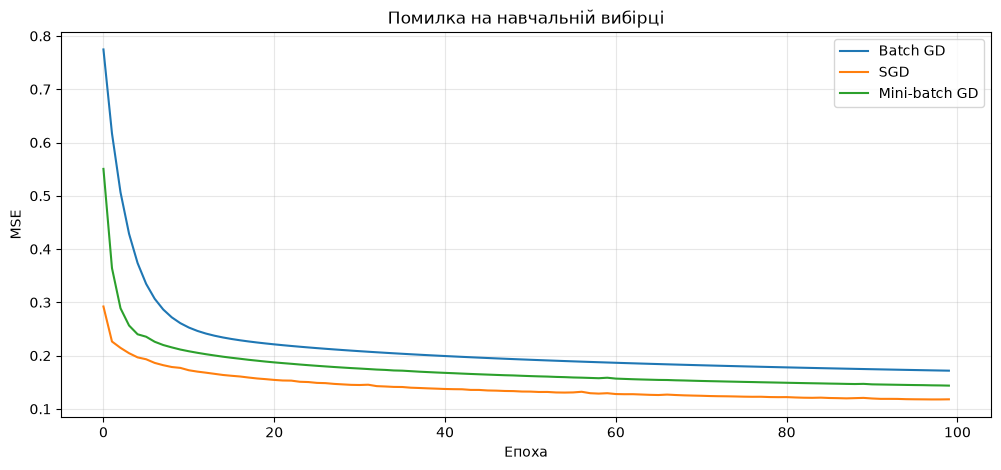

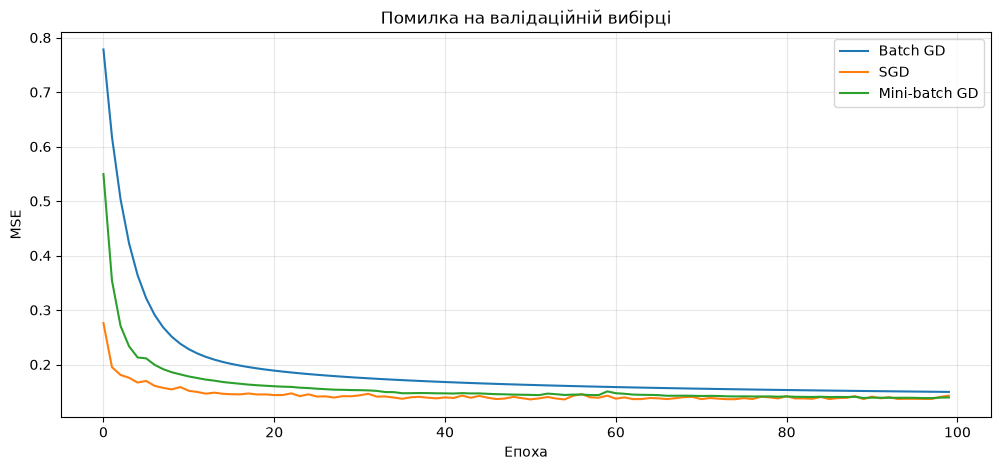

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

for name, result in results.items():
    plt.plot(result["train_losses"], label=name)

plt.title("Помилка на навчальній вибірці")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


plt.figure(figsize=(12, 5))

for name, result in results.items():
    plt.plot(result["val_losses"], label=name)

plt.title("Помилка на валідаційній вибірці")
plt.xlabel("Епоха")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [29]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

evaluation_results = []

for name, result in results.items():
    weights = result["weights"]
    bias = result["bias"]

    for dataset_name, X_data, y_original in [
        ("Train", X_train_tensor, y_train),
        ("Validation", X_val_tensor, y_val),
        ("Test", X_test_tensor, y_test)
    ]:
        # Прогноз у стандартизованому масштабі
        with torch.no_grad():
            predictions_scaled = predict_linear(
                X_data, weights, bias
            ).cpu().numpy().reshape(-1)

        # Повертаємо прогноз до цін у доларах
        predictions = predictions_scaled * y_std + y_mean
        actual = y_original.to_numpy(dtype=np.float64)

        evaluation_results.append({
            "Метод": name,
            "Вибірка": dataset_name,
            "R²": r2_score(actual, predictions),
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": np.sqrt(mean_squared_error(actual, predictions))
        })

evaluation_df = pd.DataFrame(evaluation_results)

print(evaluation_df.round(3).to_string(index=False))

        Метод    Вибірка    R²       MAE      RMSE
     Batch GD      Train 0.828 18305.273 31982.481
     Batch GD Validation 0.851 19552.917 29860.736
     Batch GD       Test 0.834 20546.625 35713.926
          SGD      Train 0.882 16408.611 26506.169
          SGD Validation 0.858 18699.828 29165.889
          SGD       Test 0.848 20373.412 34132.738
Mini-batch GD      Train 0.856 17362.792 29253.577
Mini-batch GD Validation 0.861 18642.638 28831.275
Mini-batch GD       Test 0.845 20063.398 34470.635


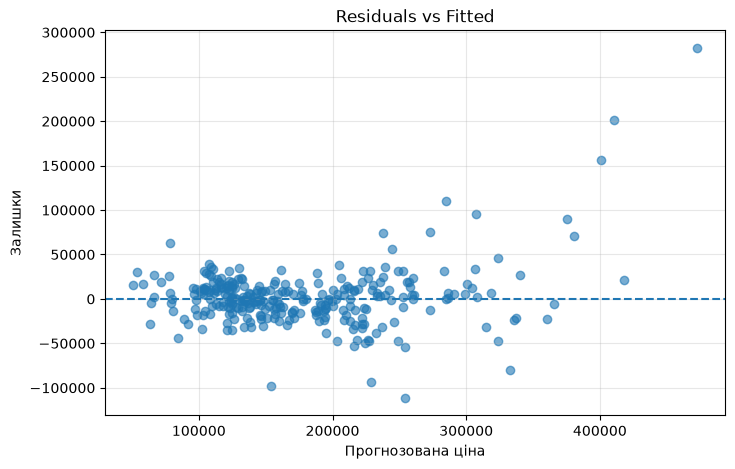

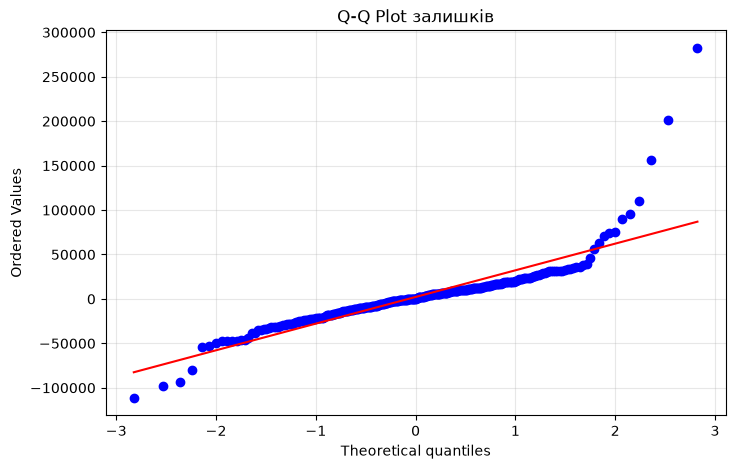

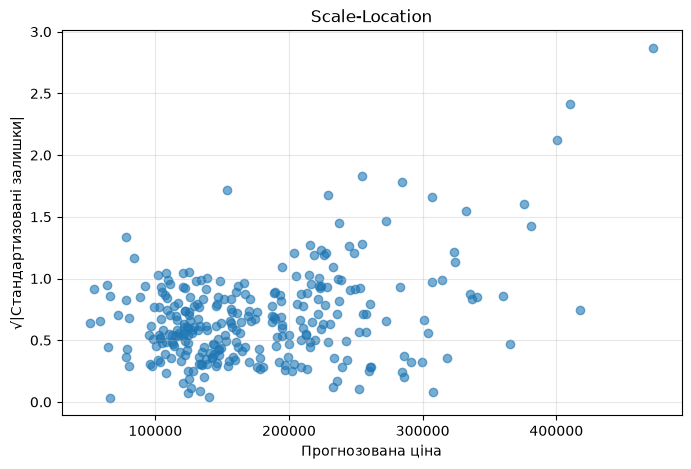

Статистика Shapiro-Wilk: 0.7742
p-value: 0.000000


In [30]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from scipy import stats

# Обираємо модель SGD
best_model = results["SGD"]
weights = best_model["weights"]
bias = best_model["bias"]

# Прогноз на тестовій вибірці
with torch.no_grad():
    predictions_scaled = predict_linear(
        X_test_tensor, weights, bias
    ).cpu().numpy().ravel()

# Повертаємо ціну до початкового масштабу
y_pred = predictions_scaled * y_std + y_mean
y_actual = y_test.to_numpy(dtype=np.float64)

# Обчислюємо залишки
residuals = y_actual - y_pred

# 1. Залишки проти прогнозованих значень
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, linestyle="--")
plt.title("Residuals vs Fitted")
plt.xlabel("Прогнозована ціна")
plt.ylabel("Залишки")
plt.grid(alpha=0.3)
plt.show()

# 2. Q-Q графік
plt.figure(figsize=(8, 5))
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("Q-Q Plot залишків")
plt.grid(alpha=0.3)
plt.show()

# 3. Scale-Location
standardized_residuals = (
    residuals - residuals.mean()
) / residuals.std()

plt.figure(figsize=(8, 5))
plt.scatter(
    y_pred,
    np.sqrt(np.abs(standardized_residuals)),
    alpha=0.6
)
plt.title("Scale-Location")
plt.xlabel("Прогнозована ціна")
plt.ylabel("√|Стандартизовані залишки|")
plt.grid(alpha=0.3)
plt.show()

# 4. Тест Шапіро — Вілка
# Для великих вибірок перевіряємо випадкову підвибірку
rng = np.random.default_rng(42)
sample = rng.choice(
    residuals,
    size=min(500, len(residuals)),
    replace=False
)

shapiro_stat, shapiro_p = stats.shapiro(sample)

print(f"Статистика Shapiro-Wilk: {shapiro_stat:.4f}")
print(f"p-value: {shapiro_p:.6f}")

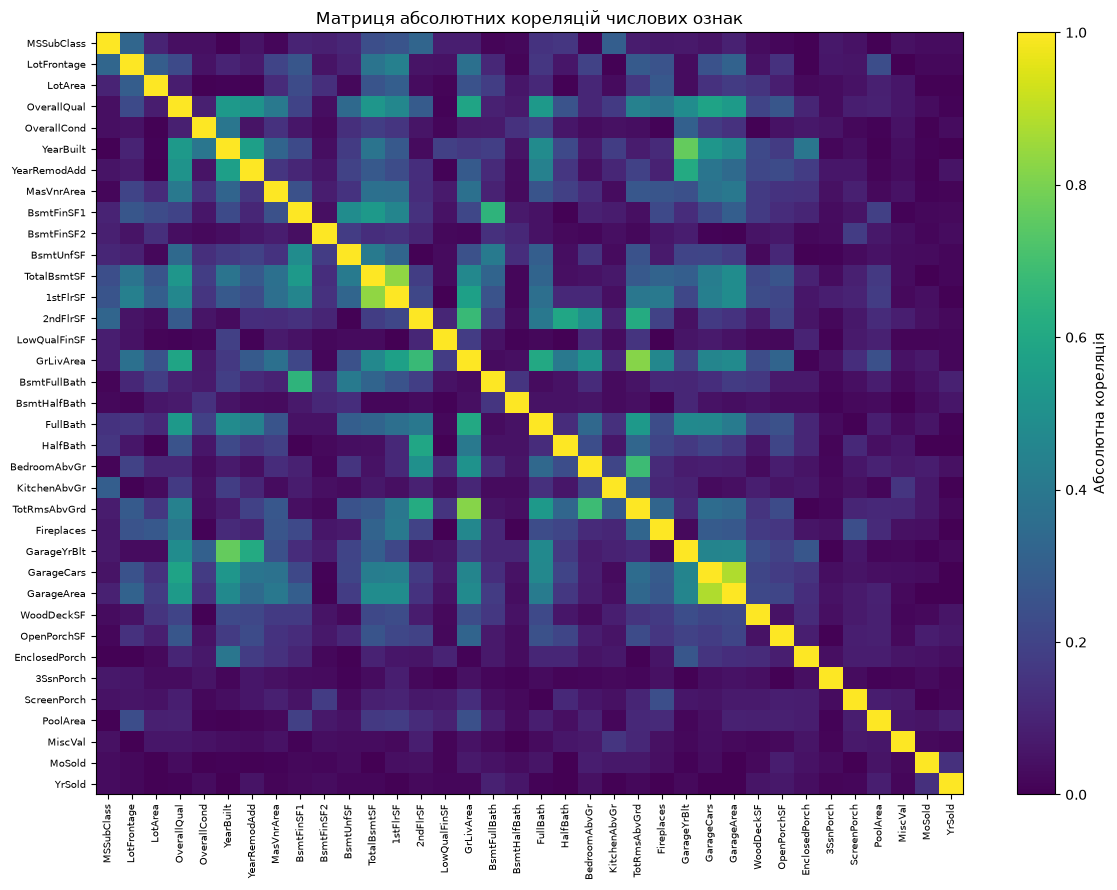

Пари ознак із кореляцією понад 0.8:
GarageCars   GarageArea      0.881096
TotalBsmtSF  1stFlrSF        0.832162
GrLivArea    TotRmsAbvGrd    0.817100
dtype: float64

Ознаки з найбільшими значеннями VIF:
      Ознака          VIF
  BsmtFinSF2 1.000800e+15
LowQualFinSF 1.000800e+15
  BsmtFinSF1 1.000800e+15
   GrLivArea 1.000800e+15
   BsmtUnfSF 1.000800e+15
 TotalBsmtSF 1.000800e+15
    1stFlrSF 1.000800e+15
    2ndFlrSF 1.000800e+15
  GarageArea 5.541000e+00
  GarageCars 5.479000e+00
TotRmsAbvGrd 5.170000e+00
   YearBuilt 5.029000e+00
 GarageYrBlt 3.171000e+00
 OverallQual 3.168000e+00
    FullBath 2.871000e+00


/var/folders/tl/8ydlsgz16zjd20268dwwnlh00000gn/T/ipykernel_30484/445169036.py:58: UserWarning: The design matrix is poorly conditioned (condition number=1.83e+16). VIF calculations may be numerically unstable.
  "VIF": variance_inflation_factor(
/Users/ulianaksondz/Documents/linear_regression_lab/.venv/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/ulianaksondz/Documents/linear_regression_lab/.venv/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/Users/ulianaksondz/Documents/linear_regression_lab/.venv/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficie

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Числові ознаки до кодування категоріальних змінних
numeric_train = X_train[numeric_features].copy()

# Заповнюємо пропуски медіанами, обчисленими на Train
numeric_train = numeric_train.fillna(numeric_train.median())

# Кореляційна матриця
corr_matrix = numeric_train.corr()

plt.figure(figsize=(12, 9))
plt.imshow(corr_matrix.abs(), aspect="auto", vmin=0, vmax=1)
plt.colorbar(label="Абсолютна кореляція")
plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90,
    fontsize=7
)
plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    fontsize=7
)
plt.title("Матриця абсолютних кореляцій числових ознак")
plt.tight_layout()
plt.show()

# Знаходимо пари з високою кореляцією
upper_triangle = corr_matrix.abs().where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper_triangle.stack()
    .sort_values(ascending=False)
)

print("Пари ознак із кореляцією понад 0.8:")
print(high_corr[high_corr > 0.8].head(15))

# VIF для числових ознак
X_vif = numeric_train.loc[:, numeric_train.nunique() > 1].copy()

# Стандартизуємо числові ознаки для чисельної стабільності
X_vif = (X_vif - X_vif.mean()) / X_vif.std()
X_vif = X_vif.replace([np.inf, -np.inf], np.nan).dropna(axis=1)

vif_results = []

for i, column in enumerate(X_vif.columns):
    vif_results.append({
        "Ознака": column,
        "VIF": variance_inflation_factor(
            X_vif.to_numpy(), i
        )
    })

vif_df = pd.DataFrame(vif_results).sort_values(
    "VIF", ascending=False
)

print("\nОзнаки з найбільшими значеннями VIF:")
print(vif_df.head(15).round(3).to_string(index=False))

In [32]:
# Найсильніші кореляції між різними ознаками
print("Найсильніші кореляції:")
print(high_corr.head(5).round(3).to_string())

# Кількість пар із високою кореляцією
print("\nКількість пар із |кореляцією| > 0.8:",
      int((high_corr > 0.8).sum()))

# Найбільші значення VIF
print("\nМаксимальний VIF:", round(vif_df["VIF"].max(), 2))
print("Кількість ознак із VIF > 5:", int((vif_df["VIF"] > 5).sum()))
print("Кількість ознак із VIF > 10:", int((vif_df["VIF"] > 10).sum()))

Найсильніші кореляції:
GarageCars    GarageArea      0.881
TotalBsmtSF   1stFlrSF        0.832
GrLivArea     TotRmsAbvGrd    0.817
YearBuilt     GarageYrBlt     0.762
BedroomAbvGr  TotRmsAbvGrd    0.684

Кількість пар із |кореляцією| > 0.8: 3

Максимальний VIF: 1000799917193443.5
Кількість ознак із VIF > 5: 12
Кількість ознак із VIF > 10: 8


In [33]:
# Перевірка константних ознак
constant_features = [
    col for col in numeric_train.columns
    if numeric_train[col].nunique(dropna=True) <= 1
]

print("Константні ознаки:", constant_features)

# Перевірка точних дублікатів між числовими ознаками
duplicate_pairs = []

columns = numeric_train.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        a = numeric_train[columns[i]]
        b = numeric_train[columns[j]]

        if a.equals(b):
            duplicate_pairs.append((columns[i], columns[j]))

print("Кількість пар точних дублікатів:", len(duplicate_pairs))
print("Перші знайдені дублікати:", duplicate_pairs[:10])

Константні ознаки: []
Кількість пар точних дублікатів: 0
Перші знайдені дублікати: []


In [34]:
def train_ridge(
    X, y, X_val, y_val,
    learning_rate=0.001,
    epochs=100,
    alpha=0.01
):
    torch.manual_seed(42)

    n_samples, n_features = X.shape
    weights = torch.zeros((n_features, 1), dtype=torch.float32)
    bias = torch.tensor(0.0, dtype=torch.float32)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        predictions = X @ weights + bias
        errors = predictions - y

        # Градієнти MSE + L2-регуляризація
        grad_weights = (
            (2.0 / n_samples) * (X.T @ errors)
            + 2.0 * alpha * weights
        )
        grad_bias = 2.0 * torch.mean(errors)

        weights -= learning_rate * grad_weights
        bias -= learning_rate * grad_bias

        train_loss = mse_loss(X @ weights + bias, y).item()
        val_loss = mse_loss(X_val @ weights + bias, y_val).item()

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if not np.isfinite(train_loss) or not np.isfinite(val_loss):
            raise ValueError("Навчання нестабільне. Зменш learning_rate.")

    return {
        "weights": weights,
        "bias": bias,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "alpha": alpha
    }


print("Функцію Ridge-регресії визначено.")

Функцію Ridge-регресії визначено.


In [35]:
ridge_results = {}

for alpha in [0.001, 0.01, 0.1, 1.0]:
    model = train_ridge(
        X_train_tensor,
        y_train_tensor,
        X_val_tensor,
        y_val_tensor,
        learning_rate=0.001,
        epochs=100,
        alpha=alpha
    )

    ridge_results[alpha] = model

    print(
        f"alpha={alpha:<6} | "
        f"Train MSE={model['train_losses'][-1]:.6f} | "
        f"Validation MSE={model['val_losses'][-1]:.6f}"
    )

best_alpha = min(
    ridge_results,
    key=lambda a: ridge_results[a]["val_losses"][-1]
)

print(f"\nНайкраще alpha: {best_alpha}")

alpha=0.001  | Train MSE=0.267502 | Validation MSE=0.246245
alpha=0.01   | Train MSE=0.267672 | Validation MSE=0.246448
alpha=0.1    | Train MSE=0.269386 | Validation MSE=0.248495
alpha=1.0    | Train MSE=0.287681 | Validation MSE=0.269834

Найкраще alpha: 0.001


In [36]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import torch

# Найкраща Ridge-модель за Validation MSE
ridge_best = ridge_results[best_alpha]

with torch.no_grad():
    ridge_pred_scaled = (
        X_test_tensor @ ridge_best["weights"] + ridge_best["bias"]
    ).cpu().numpy().ravel()

# Повертаємо ціну до початкового масштабу
ridge_pred = ridge_pred_scaled * y_std + y_mean
y_actual = y_test.to_numpy(dtype=np.float64)

ridge_test_metrics = {
    "Модель": "Ridge",
    "Alpha": best_alpha,
    "R²": r2_score(y_actual, ridge_pred),
    "MAE": mean_absolute_error(y_actual, ridge_pred),
    "RMSE": np.sqrt(mean_squared_error(y_actual, ridge_pred))
}

print(pd.DataFrame([ridge_test_metrics]).round(3).to_string(index=False))

Модель  Alpha    R²       MAE      RMSE
 Ridge  0.001 0.737 24768.959 44954.925
